Lecture 13: Exploratory Data Analysis of the Tips Data Set Part 2

In [2]:
#Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
#Read in csv data to create DataFrame
#from https://github.com/wesm/pydata-book/blob/3rd-edition/examples/tips.csv
tips = pd.read_csv('tips.csv')
tips.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4


In [4]:
#Add a column with the tip percentage
tips['percent'] = tips['tip']/tips['total_bill']*100
tips

,total_bill,tip,smoker,day,time,size,percent
0,16.99,1.01,No,Sun,Dinner,2,5.944673
1,10.34,1.66,No,Sun,Dinner,3,16.054159
2,21.01,3.50,No,Sun,Dinner,3,16.658734
3,23.68,3.31,No,Sun,Dinner,2,13.978041
4,24.59,3.61,No,Sun,Dinner,4,14.680765
...,...,...,...,...,...,...,...
239,29.03,5.92,No,Sat,Dinner,3,20.392697
240,27.18,2.00,Yes,Sat,Dinner,2,7.358352
241,22.67,2.00,Yes,Sat,Dinner,2,8.822232
242,17.82,1.75,No,Sat,Dinner,2,9.820426


In [5]:
groupsize = tips.groupby('size')['percent'].mean()
groupsize

size
1    21.729202
2    16.571919
3    15.215685
4    14.594901
5    14.149549
6    15.622920
Name: percent, dtype: float64

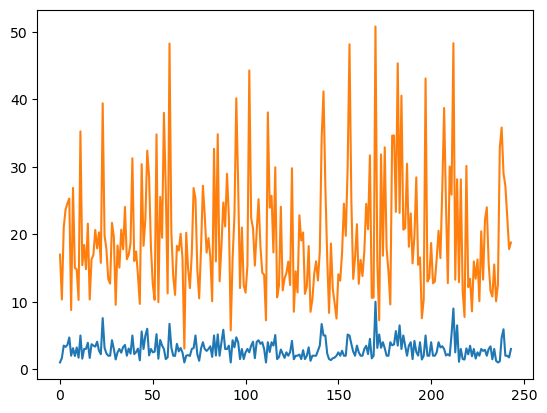

In [6]:
plt.plot(tips["tip"])
plt.plot(tips["total_bill"])


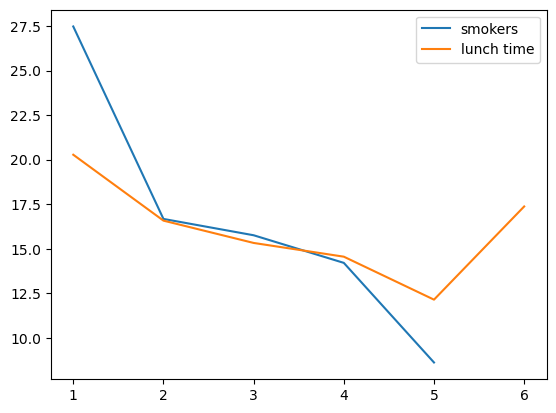

In [7]:
smoker= tips[tips['smoker'] == 'Yes' ]
plt.plot(smoker.groupby('size')['percent'].mean(), label = 'smokers')
lunch= tips[tips['time'] == 'Lunch' ]
plt.plot(lunch.groupby('size')['percent'].mean(), label = 'lunch time')
plt.legend()

In [8]:
timesize = tips.groupby(['time', 'size'])['percent'].mean()
timesize


time    size
Dinner  1       23.183197
        2       16.570395
        3       15.199487
        4       14.601680
        5       14.652219
        6       10.379905
Lunch   1       20.275206
        2       16.574967
        3       15.322597
        4       14.551515
        5       12.138869
        6       17.370592
Name: percent, dtype: float64

<Axes: xlabel='time,size'>

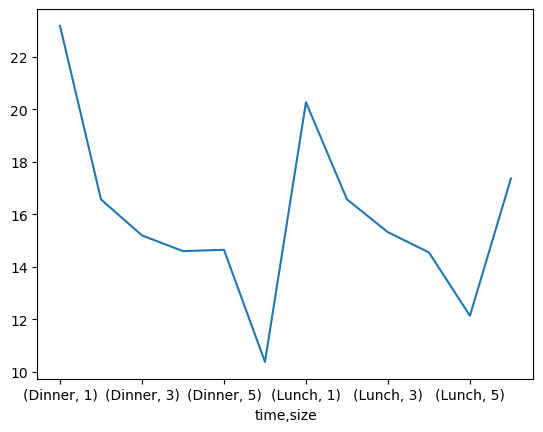

In [9]:
timesize.plot()

<Axes: xlabel='time'>

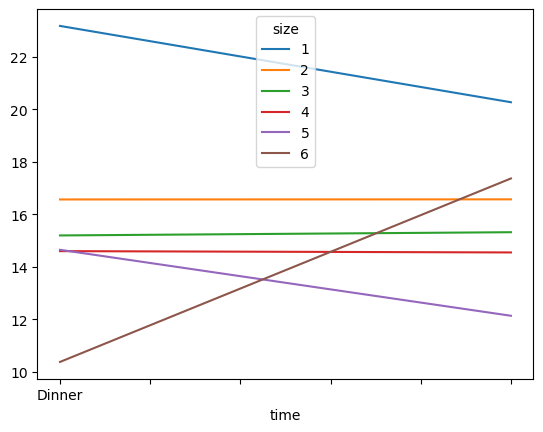

In [10]:
timesize.unstack().plot()

In [11]:
sizetime = tips.groupby(['size', 'time'])['percent'].mean()
sizetime

size  time  
1     Dinner    23.183197
      Lunch     20.275206
2     Dinner    16.570395
      Lunch     16.574967
3     Dinner    15.199487
      Lunch     15.322597
4     Dinner    14.601680
      Lunch     14.551515
5     Dinner    14.652219
      Lunch     12.138869
6     Dinner    10.379905
      Lunch     17.370592
Name: percent, dtype: float64

<Axes: xlabel='size,time'>

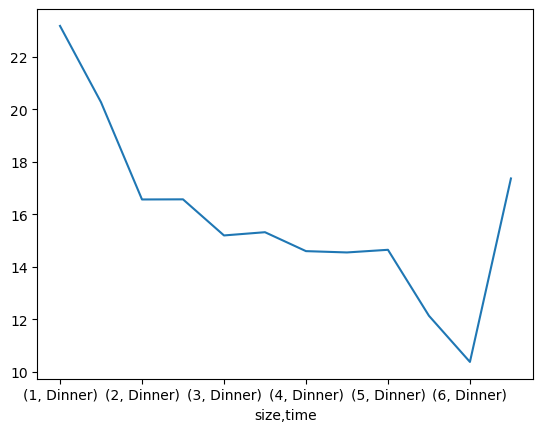

In [12]:
sizetime.plot()

<Axes: xlabel='size'>

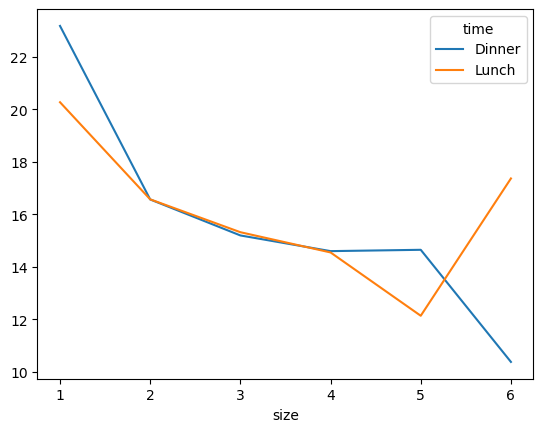

In [13]:
sizetime.unstack().plot()

(array([76.,  0.,  0., 87.,  0.,  0., 62.,  0.,  0., 19.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

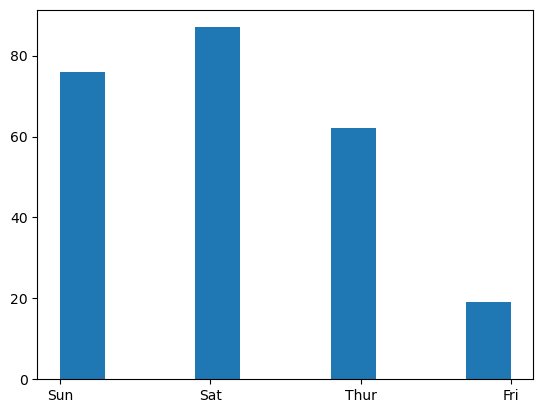

In [14]:
plt.hist(tips['day'], bins = 10)

(array([  4., 156.,  38.,  37.,   5.,   4.]),
 array([1.        , 1.83333333, 2.66666667, 3.5       , 4.33333333,
        5.16666667, 6.        ]),
 <BarContainer object of 6 artists>)

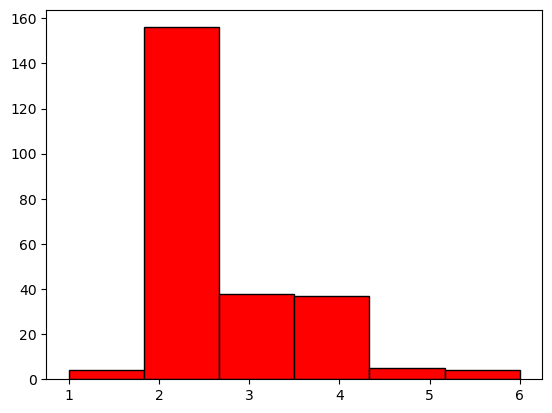

In [15]:
plt.hist(tips['size'], bins = 6, facecolor = 'red', edgecolor = 'black')

(array([ 1.,  0.,  0.,  3.,  2.,  4.,  6.,  4.,  4.,  7.,  8.,  3., 10.,
        10., 11., 20., 18., 18., 13.,  9., 11., 10., 10., 14., 15.,  5.,
         3.,  5.,  5.,  2.,  3.,  0.,  1.,  2.,  1.,  0.,  2.,  1.,  0.,
         0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([ 3.56381359,  4.23852028,  4.91322697,  5.58793366,  6.26264035,
         6.93734704,  7.61205374,  8.28676043,  8.96146712,  9.63617381,
        10.3108805 , 10.98558719, 11.66029389, 12.33500058, 13.00970727,
        13.68441396, 14.35912065, 15.03382734, 15.70853404, 16.38324073,
        17.05794742, 17.73265411, 18.4073608 , 19.0820675 , 19.75677419,
        20.43148088, 21.10618757, 21.78089426, 22.45560095, 23.130307

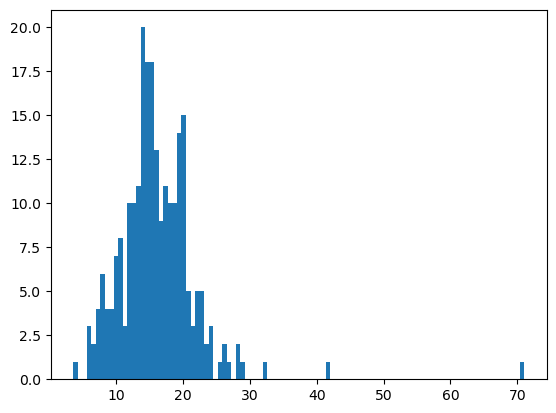

In [16]:
plt.hist(tips['percent'], bins = 100)

In [17]:
isinstance(tips, pd.DataFrame)

True

<Axes: ylabel='Frequency'>

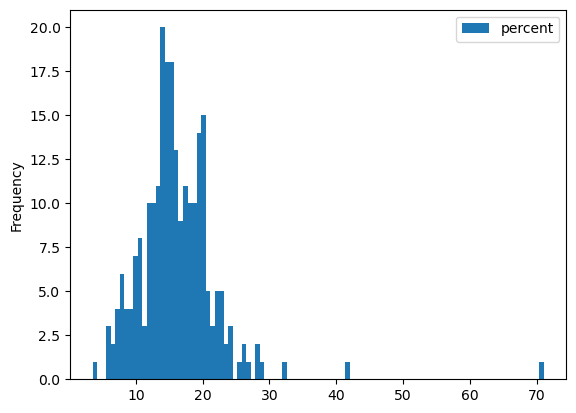

In [18]:

tips.plot.hist(y = 'percent', bins = 100)

(array([ 1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  2.,  3.,  0.,  5.,  0.,
         3.,  5., 10.,  3.,  5.,  4.,  7.,  8., 10.,  4.,  6.,  3.,  7.,
         6., 11.,  6.,  7.,  7., 10.,  6.,  1.,  4.,  4.,  9.,  6.,  2.,
         2.,  3.,  5.,  2.,  4.,  4.,  3.,  3.,  3.,  1.,  3.,  4.,  0.,
         2.,  2.,  2.,  1.,  4.,  2.,  0.,  2.,  1.,  1.,  3.,  0.,  0.,
         1.,  4.,  1.,  1.,  0.,  0.,  0.,  0.,  2.,  1.,  0.,  1.,  1.,
         1.,  1.,  0.,  0.,  0.,  1.,  0.,  0.,  1.,  0.,  1.,  0.,  0.,
         0.,  0.,  0.,  3.,  0.,  0.,  0.,  0.,  1.]),
 array([ 3.07  ,  3.5474,  4.0248,  4.5022,  4.9796,  5.457 ,  5.9344,
         6.4118,  6.8892,  7.3666,  7.844 ,  8.3214,  8.7988,  9.2762,
         9.7536, 10.231 , 10.7084, 11.1858, 11.6632, 12.1406, 12.618 ,
        13.0954, 13.5728, 14.0502, 14.5276, 15.005 , 15.4824, 15.9598,
        16.4372, 16.9146, 17.392 , 17.8694, 18.3468, 18.8242, 19.3016,
        19.779 , 20.2564, 20.7338, 21.2112, 21.6886, 22.166 , 22.6434,
        

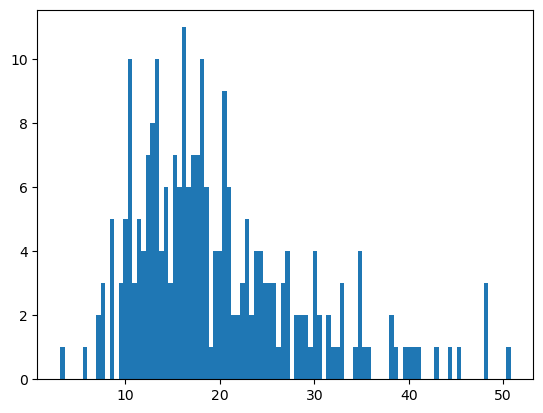

In [19]:
plt.hist(tips['total_bill'], bins = 100)

<Axes: xlabel='size'>

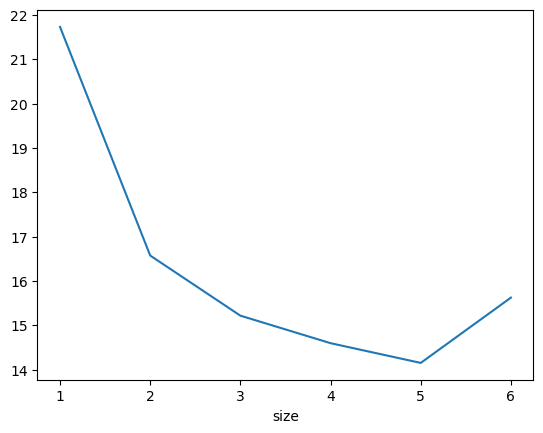

In [20]:
groupsize.plot.line()

<Axes: title={'center': 'Percent Tip by Group Size'}, xlabel='size', ylabel='Percent Tip'>

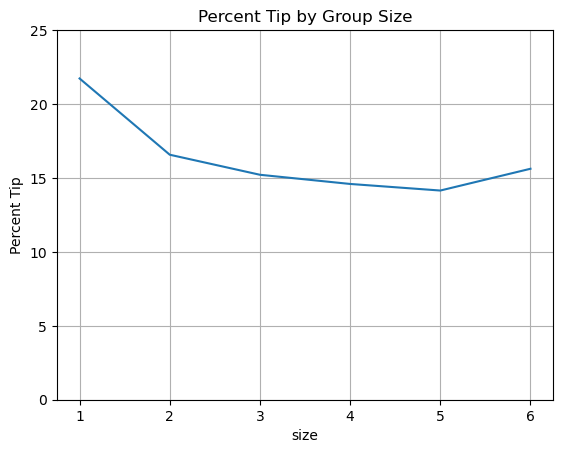

In [21]:
groupsize.plot.line(title='Percent Tip by Group Size', ylabel='Percent Tip', ylim=(0,25), grid=True)

<Axes: xlabel='size'>

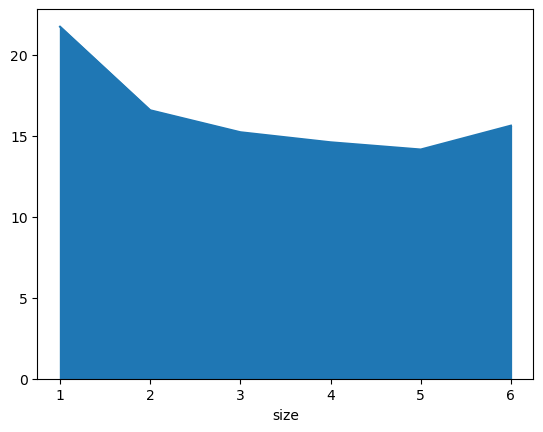

In [22]:
groupsize.plot.area()

<Axes: xlabel='total_bill', ylabel='tip'>

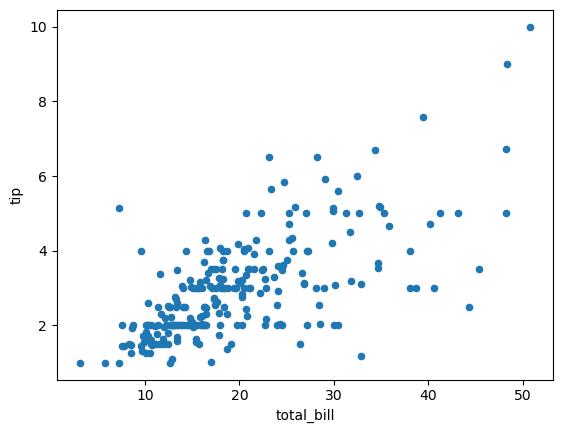

In [23]:
tips.plot.scatter(x = 'total_bill', y = 'tip')

In [24]:
import seaborn as sns

<Axes: xlabel='total_bill', ylabel='tip'>

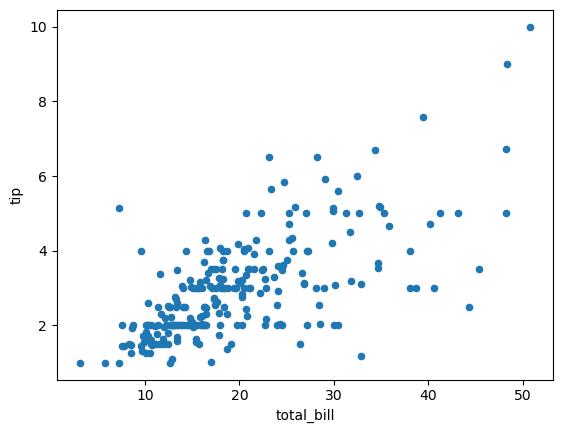

In [25]:
tips.plot.scatter(x='total_bill', y = 'tip')
#tips.plot.scatter(x='total_bill', y = 'line')

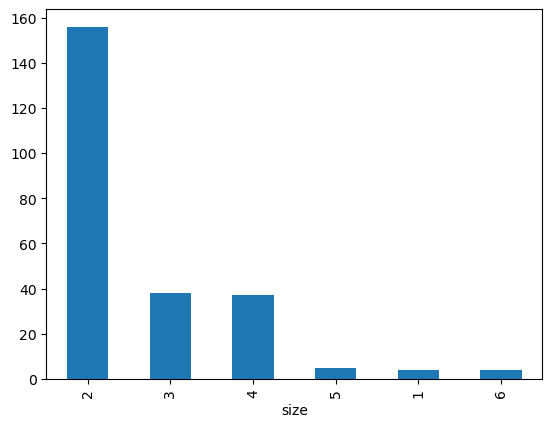

In [26]:
tipscount = tips['size'].value_counts().plot(kind = 'bar')

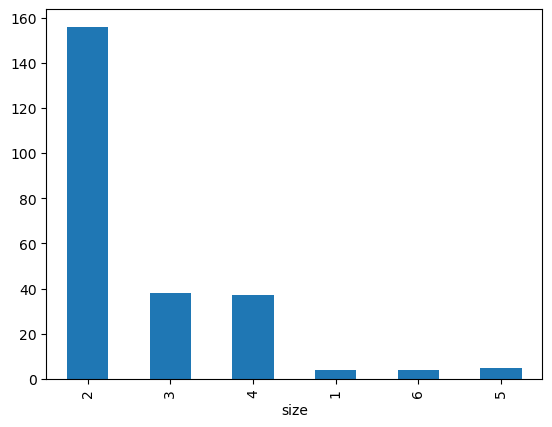

In [27]:
tipscount = tips['size'].value_counts(sort=False).plot(kind = 'bar')

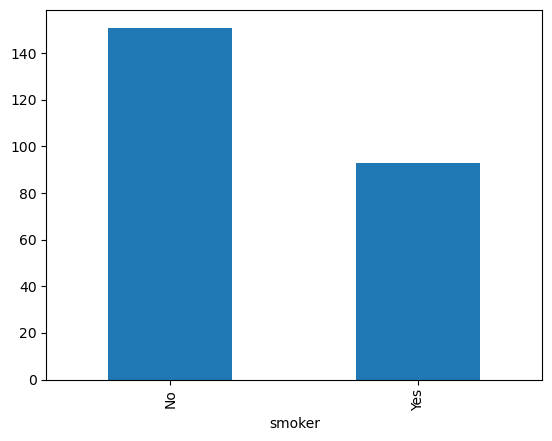

In [28]:
smoke = tips['smoker'].value_counts().plot(kind = 'bar')

<Axes: ylabel='Density'>

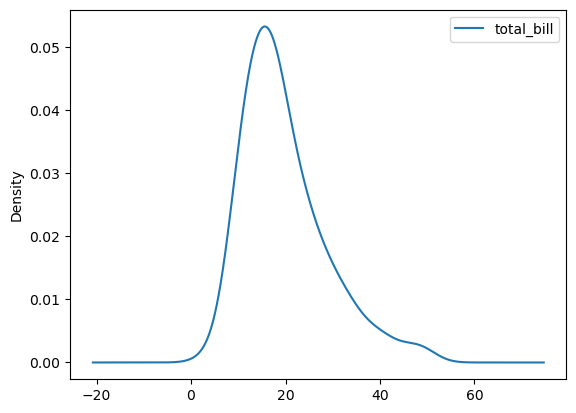

In [29]:
tips.plot.density(y ='total_bill')

<Axes: >

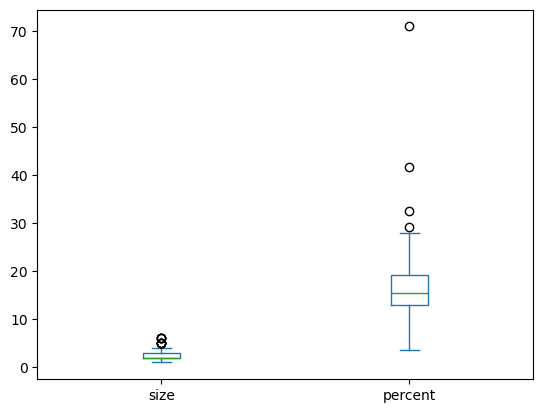

In [30]:
subtips = tips[['size', 'percent']]
subtips.plot.box()

<Axes: >

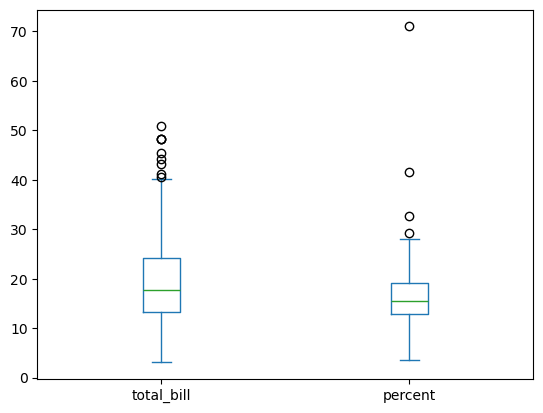

In [31]:
subtips = tips[['total_bill', 'percent']]
subtips.plot.box()

<Axes: ylabel='tip'>

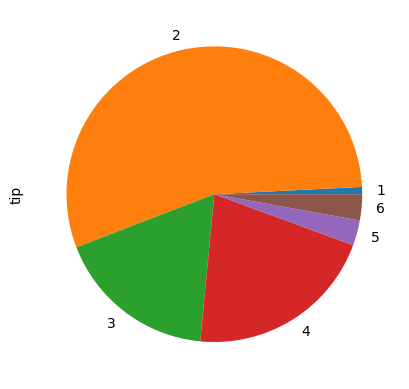

In [32]:
tips.groupby('size')['tip'].sum().plot.pie()

<Axes: ylabel='total_bill'>

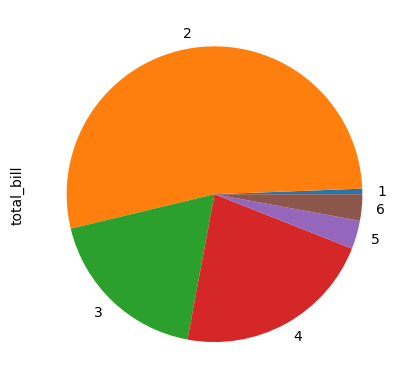

In [33]:
tips.groupby('size')['total_bill'].sum().plot.pie()

<Axes: ylabel='count'>

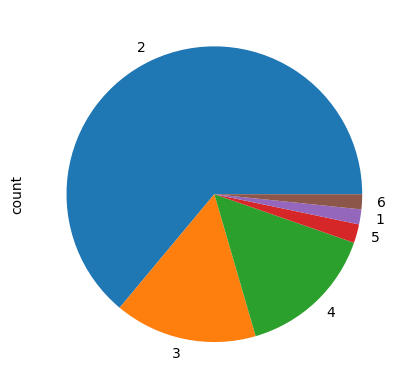

In [34]:
tips['size'].value_counts().plot.pie()

(array([ 5.,  2.,  3.,  1.,  3., 12.,  4.,  6.,  4.,  1.,  4., 39.,  1.,
         7.,  4.,  0., 13.,  5.,  1.,  5.,  2.,  1., 25.,  7.,  6.,  4.,
         4., 13.,  2.,  2.,  4.,  0.,  1., 13.,  2.,  2.,  3.,  1.,  1.,
         0.,  1.,  2.,  0.,  0., 10.,  1.,  5.,  0.,  0.,  0.,  0.,  2.,
         0.,  1.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  2.,  0.,  2.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([ 1.  ,  1.09,  1.18,  1.27,  1.36,  1.45,  1.54,  1.63,  1.72,
         1.81,  1.9 ,  1.99,  2.08,  2.17,  2.26,  2.35,  2.44,  2.53,
         2.62,  2.71,  2.8 ,  2.89,  2.98,  3.07,  3.16,  3.25,  3.34,
         3.43,  3.52,  3.61,  3.7 ,  3.79,  3.88,  3.97,  4.06,  4.15,
         4.24,  4.33,  4.42,  4.51,  4.6 ,  4.69,  4.78,  4.87,  4.96,
         5.05,  5.14,  5.23,  5.32,  5.41,  5.5 ,  5.59,  5.68,  5.77,
        

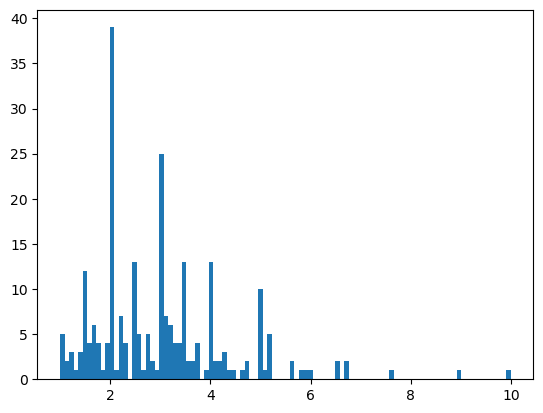

In [35]:
plt.hist(tips['tip'], bins = 100)

(array([151.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         93.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
        0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
        0.44, 0.45, 0.

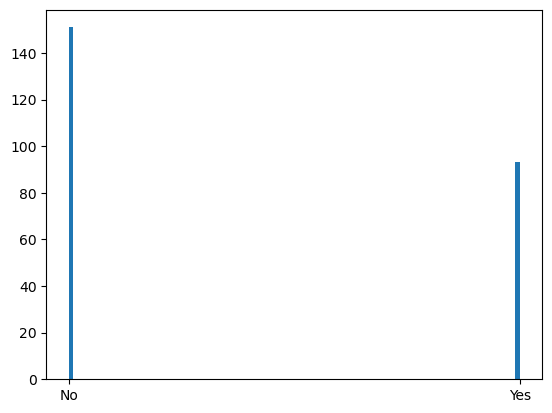

In [36]:
plt.hist(tips['smoker'], bins = 100)

(array([176.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         68.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
        0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
        0.44, 0.45, 0.

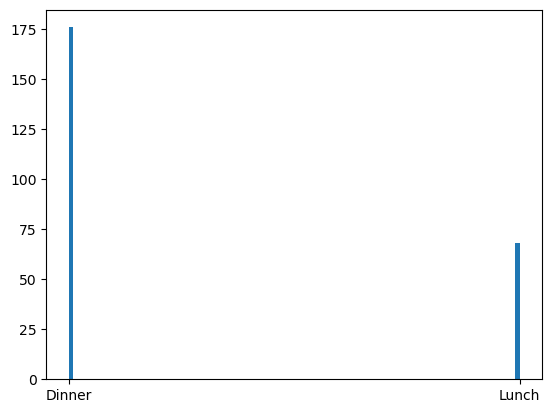

In [37]:
plt.hist(tips['time'], bins = 100)

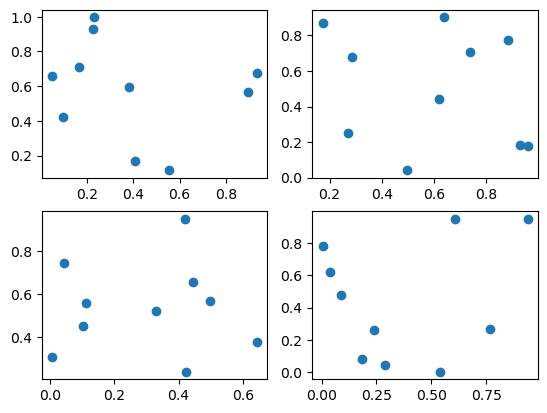

In [38]:
x1 = np.random.rand(10)
x2 = np.random.rand(10)
x3 = np.random.rand(10)
x4 = np.random.rand(10)
y1 = np.random.rand(10)
y2 = np.random.rand(10)
y3 = np.random.rand(10)
y4 = np.random.rand(10)

figure2, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)
ax1.plot(x1,y1,'o')
ax2.plot(x2,y2, 'o')
ax3.plot(x3,y3, 'o')
ax4.plot(x4,y4, 'o')

In [39]:
anscombe = sns.load_dataset("anscombe")
anscombe


,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


In [40]:
anscombe.groupby('dataset').mean()

,x,y
dataset,,
I,9.0,7.500909
II,9.0,7.500909
III,9.0,7.500000
IV,9.0,7.500909


In [41]:
anscombe.groupby('dataset').var()

,x,y
dataset,,
I,11.0,4.127269
II,11.0,4.127629
III,11.0,4.122620
IV,11.0,4.123249


In [42]:
anscombe.groupby('dataset').corr()

x         y
dataset                      
I       x  1.000000  0.816421
        y  0.816421  1.000000
II      x  1.000000  0.816237
        y  0.816237  1.000000
III     x  1.000000  0.816287
        y  0.816287  1.000000
IV      x  1.000000  0.816521
        y  0.816521  1.000000

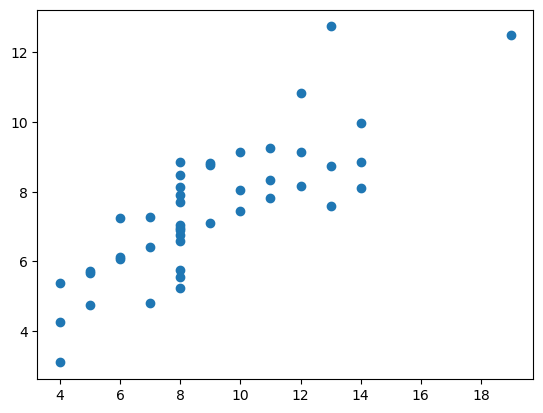

In [43]:
plt.plot(anscombe['x'], anscombe['y'],'o')

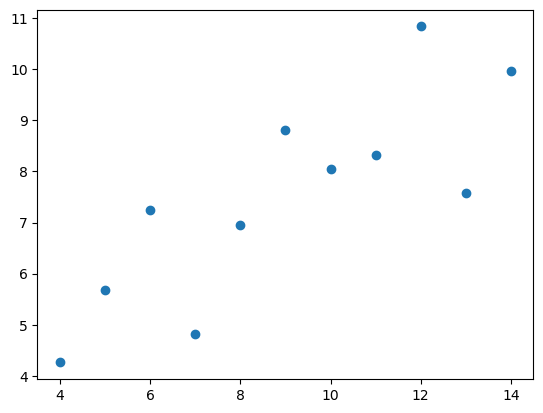

In [44]:
data1 = anscombe[anscombe['dataset'] == 'I']
plt.plot(data1['x'], data1['y'], 'o')

In [45]:
data2 = anscombe[anscombe['dataset'] == 'II']
data3 = anscombe[anscombe['dataset'] == 'III']
data4 = anscombe[anscombe['dataset'] == 'IV']

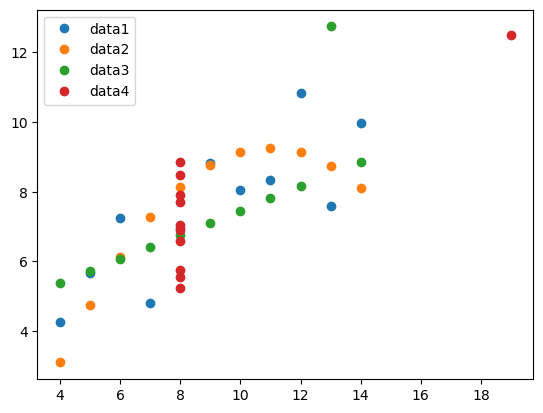

In [46]:
fig1, axes = plt.subplots()
axes.plot(data1['x'], data1['y'], 'o', label='data1')
axes.plot(data2['x'], data2['y'], 'o', label='data2')
axes.plot(data3['x'], data3['y'], 'o', label='data3')
axes.plot(data4['x'], data4['y'], 'o', label='data4')
axes.legend(loc='best')

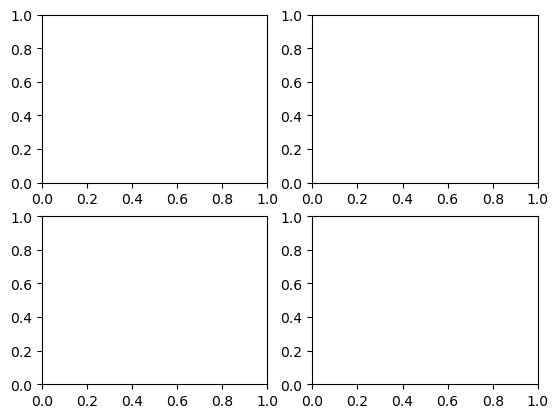

In [47]:
fig = plt.figure()
axes1 = fig.add_subplot(2, 2, 1)
axes2 = fig.add_subplot(2, 2, 2)
axes3 = fig.add_subplot(2, 2, 3)
axes4 = fig.add_subplot(2, 2, 4)

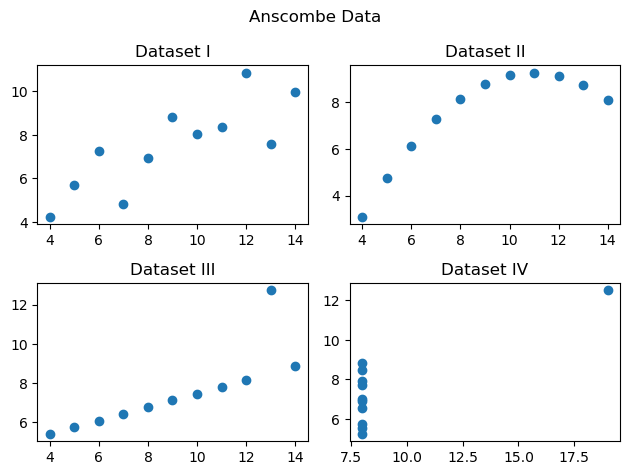

In [48]:
fig = plt.figure()
axes1 = fig.add_subplot(2, 2, 1)
axes2 = fig.add_subplot(2, 2, 2)
axes3 = fig.add_subplot(2, 2, 3)
axes4 = fig.add_subplot(2, 2, 4)
axes1.plot(data1['x'], data1['y'], 'o')
axes2.plot(data2['x'], data2['y'], 'o')
axes3.plot(data3['x'], data3['y'], 'o')
axes4.plot(data4['x'], data4['y'], 'o')
fig.suptitle("Anscombe Data")
axes1.set_title("Dataset I")
axes2.set_title("Dataset II")
axes3.set_title("Dataset III")
axes4.set_title("Dataset IV")
fig.tight_layout()

<Axes: >

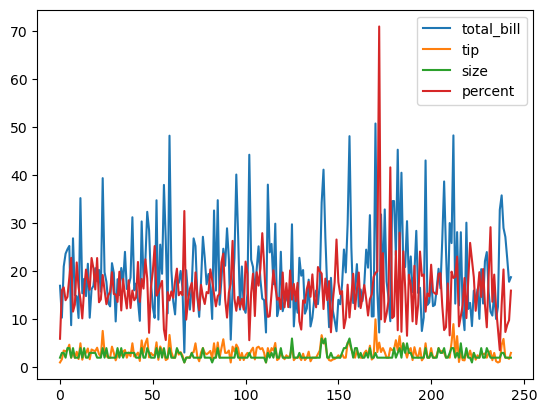

In [49]:
tips.plot()

<Axes: xlabel='tip', ylabel='total_bill'>

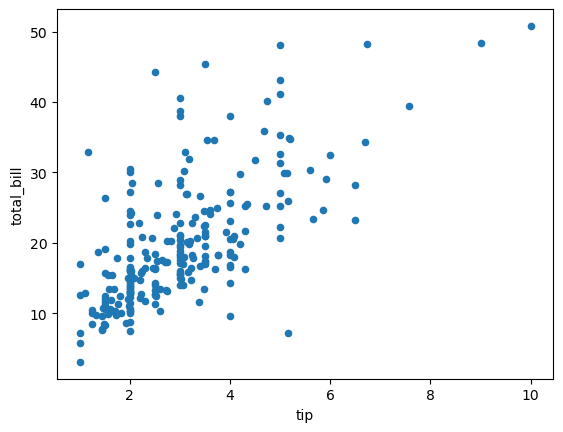

In [50]:
tips.plot.scatter('tip','total_bill')

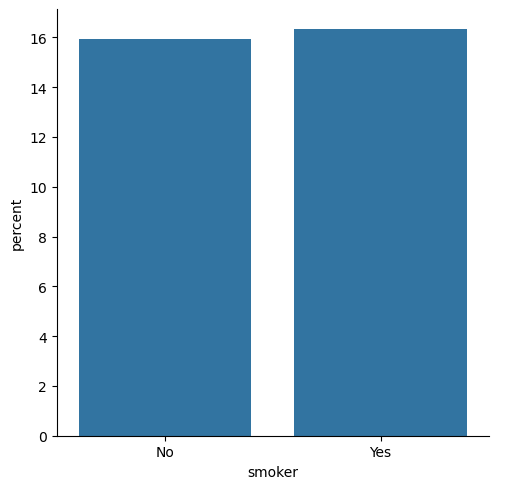

In [51]:
import seaborn as sns
sns.catplot(data=tips, kind = 'bar', x = 'smoker', y ='percent', errorbar = None)

In [52]:
group_count = pd.crosstab(tips['day'], tips['size'])
group_count

size,1,2,3,4,5,6
day,,,,,,
Fri,1,16,1,1,0,0
Sat,2,53,18,13,1,0
Sun,0,39,15,18,3,1
Thur,1,48,4,5,1,3


<Axes: xlabel='day'>

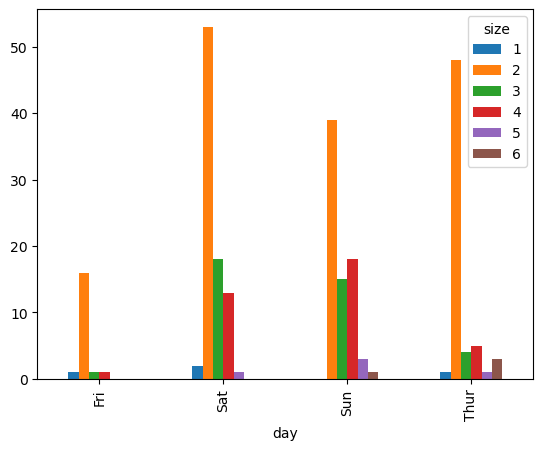

In [53]:
group_count.plot.bar()